# 20. От фотографий до собственной статической сцены

[План курса](../../README_ru.md)

На столе лежат девять фотографий скульптуры. Положения камер уже получены. Теперь можно закрыть один снимок, учиться по оставшимся восьми и в конце открыть закрытый. Если скульптура узнаётся и с той стороны, модель узнала что-то о пространстве.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'

import photo_diagnostics as inspect_photo

## Как выглядит начало

В опыте с цветными пятнами центры и размеры заданы заранее. Серый цвет одинаков у всех. Один шаг меняет RGB по трём обучающим видам одновременно. В наборе фотографий центры приходят из разреженного облака. Справа от модели доступен выбор камеры. Смещение камеры в сторону даёт дополнительный вид без фотографии-эталона. Здесь особенно заметно, что рендерер хранит одну общую сцену. Браузер уточняет цвета при закреплённой геометрии. В расчёте Python ниже откроются ещё центры, три ширины, поворот и непрозрачность.


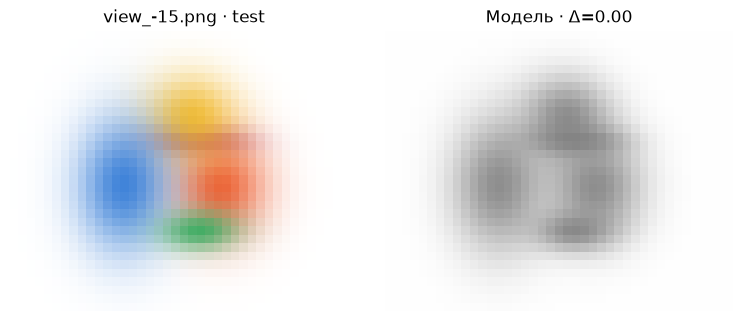

In [2]:
frames, initial = synthetic_capture()
def small_view(steps, offset):
    model, _ = fit_colors(initial, frames, int(steps))
    return view_figure(frames, model, 1, offset, lang)
display(small_view(0,0)); plt.close()
controls(small_view, steps=(0,24,1,0), offset=(-.2,.2,.005,0))


## От пикселя к первому шагу

Возьмём один красный канал. Цвет первого пятна $c=0.5$. В нашем пикселе ему достаётся вес $w=T\alpha=0.6$. Белый фон занимает оставшиеся 0.4. Рендер даёт $P=0.6\cdot0.5+0.4\cdot1=0.7$. На фотографии $Y=0.58$. Остаток $P-Y=0.12$, его квадрат $0.0144$. Увеличение красного на 0.01 увеличит $P$ на $0.6\cdot0.01=0.006$, то есть цвет уже слишком яркий.

Для квадрата ошибки производная по цвету равна $2(P-Y)w$. Множитель 2 приходит от квадрата, остаток сохраняет знак, $w$ говорит, какая доля луча вообще видит это пятно. Получается $2\cdot0.12\cdot0.6=0.144$. При размере шага 0.5 новое значение $0.5-0.5\cdot0.144=0.428$. Тогда $P=0.6568$, и квадрат остатка около $0.00590$. В полной картинке к сумме добавляются все пиксели всех обучающих видов. Пустые области дают малую информацию о конкретном пятне.

Почему первые шаги получаются такими быстрыми? При закреплённой форме веса не меняются. Для пикселя $j$ сохраняем $w_{ji}$ — вес видимого пятна $i$ — и $b_j$, долю белого фона. Тогда $P_j=b_j+\sum_i w_{ji}c_i$. Большой знак означает «сложить вклады всех пятен». Например, при весах 0.6 и 0.1, фоне 0.3 и цветах 0.5 и 0.2 выходит $0.3+0.6\cdot0.5+0.1\cdot0.2=0.62$. В коде столбец массива весов отвечает одному пятну, строка одному пикселю. Можно заранее сложить произведения весов по пикселям. Так очередной шаг RGB обходится без нового проектирования. Результат каждого канала удерживается в пределах от 0 до 1.


In [3]:
w,c,b,target = .6,.5,.4,.58
pred = b+w*c
updated = c-.5*2*(pred-target)*w
print("color:", c, "→", updated)
print("loss:", (pred-target)**2, "→", (b+w*updated-target)**2)
assert (b+w*updated-target)**2 < (pred-target)**2


color: 0.5 → 0.428
loss: 0.0144 → 0.005898240000000014


## Как два серых пятна могут дать правильный пиксель

Вид спереди оставляет от первого пятна вес 0,6, от второго — 0,1. Доля белого фона равна 0,3. Пусть красные каналы пятен равны 0,4 и 0,8. Пиксель получит $0{,}6\cdot0{,}4+0{,}1\cdot0{,}8+0{,}3=0{,}62$. Другая пара цветов, 0,45 и 0,5, даёт ровно столько же. Первое пятно добавило $0{,}6\cdot0{,}05=0{,}03$, второе забрало $0{,}1\cdot0{,}3=0{,}03$. У одной камеры нет оснований предпочесть один вариант другому.

Сбоку пятна перекрываются иначе. Теперь веса равны 0,2 и 0,5, фона снова 0,3. Первая пара цветов даст 0,78, вторая — 0,64. На боковом снимке красный равен 0,78. Вот что на самом деле добавила камера: второе измерение, в котором **по-другому смешались те же два неизвестных**.

От серого старта $(0{,}5;\,0{,}5)$ обе камеры предсказывают 0,65. Ошибки со знаком равны $+0{,}03$ и $-0{,}13$. Средний квадрат равен $(0{,}03^2+0{,}13^2)/2=0{,}0089$. Что произойдёт, если слегка прибавить красного первому пятну? Передний пиксель светлеет в 0,6 раза слабее прибавки, боковой — в 0,2 раза. Производная среднего квадрата равна $0{,}6\cdot0{,}03+0{,}2\cdot(-0{,}13)=-0{,}008$. Двойка от квадрата сократилась с делением на два измерения. Для второго пятна получится $0{,}1\cdot0{,}03+0{,}5\cdot(-0{,}13)=-0{,}062$. В обоих случаях небольшая прибавка полезна, но у второго есть куда более сильный сигнал.

В коде `W` хранит две строки весов. `W @ colors` собирает два пикселя, `W.T @ residual` возвращает их ошибки двум пятнам. Пока геометрия заморожена, выражение $W^\mathsf{T}(Wc-y)$ можно раскрыть как $(W^\mathsf{T}W)c-W^\mathsf{T}y$. Здесь $y$ — измеренный канал за вычетом фона. Обе таблицы, которые не содержат $c$, вычисляются один раз. В `fit_colors` это `gram` и `rhs`. После движения центра веса меняются, и старая таблица перестаёт описывать кадр.

<details><summary>А если второй снимок просто дублирует первый?</summary>

Обе строки весов окажутся одинаковыми. Ошибка измерения при повторной съёмке может усредниться, но две приведённые пары цветов по-прежнему неразличимы. В предельном случае пятно закрыто на всех видах. Весь его столбец весов равен нулю, и никакое изменение его цвета не оставит следа на снимках.

</details>

In [4]:
W = np.array([[.6,.1], [.2,.5]])
background = np.array([.3,.3])
red = np.array([.5,.5])
observed = np.array([.62,.78])
def two_view_loss(red):
    return np.mean((W @ red + background - observed)**2)
gradient = W.T @ (W @ red + background - observed)
eps = 1e-5
measured = [(two_view_loss(red+eps*d)-two_view_loss(red-eps*d))/(2*eps) for d in np.eye(2)]
print("∂L/∂c:", gradient, "  ΔL/Δc:", np.round(measured,6))
assert np.allclose(gradient, measured)
assert np.allclose(np.linalg.solve(W, observed-background), [.4,.8])

∂L/∂c: [-0.008 -0.062]   ΔL/Δc: [-0.008 -0.062]


## Данные, которые можно унести с собой

Теперь подставим настоящие снимки. Это **PhysicalAI-NuRec-PPISP, struktur28_auto, NVIDIA Corporation, CC BY 4.0**. В курсе девять адаптированных кадров по 160 × 120, уже без дисторсии. Восемь обучающих фотографий дали 117 триангулированных точек при известных положениях камер. Координаты и цвет этих точек не вычислялись по пикселям девятого кадра. Для быстрого опыта возьмём 24 точки и уменьшим кадр до 40 × 30. Ставим серые гауссианы с одинаковой начальной непрозрачностью. Более полное облако может дать больше деталей, но увеличит цену каждого шага. [Происхождение и преобразования фотографий](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example)

Папка `static-scene-result/capture/` в рабочем каталоге ноутбука хранит PNG, камеры, начальные параметры и метки train/test. В соседнем файле `static-scene-result/capture-browser.json` всё это упаковано для сайта. После обучения там появится `static-scene-result/static-gaussians.json` с подобранными параметрами. В выводе после проверки сохранённой модели виден путь относительно рабочей папки. Выражение `model_path.resolve()` в ноутбуке возвращает полный локальный путь вместе с именем файла.

Для своей съёмки меняется первая строка следующего опыта, где задаются `photos, seed`. Допустим, в собственной съёмке для оценки отложена фотография `IMG_0012.jpg`. Если папка `capture` из опыта с COLMAP лежит в рабочей директории, загрузка выглядит так.

```python
photos, seed = load_colmap(
    Path("capture/text"), Path("capture/undistorted/images"),
    max_side=40, max_points=24, test_names=["IMG_0012.jpg"],
)
```

Имя должно совпасть с записью в `images.txt`, включая расширение и вложенные каталоги. Кадр среди почти неподвижной серии дублей мало скажет о новом ракурсе. Числа 40 и 24 сохраняют тот же предел размера кадра и числа пятен, что в опыте со скульптурой.

У собственной реконструкции, рассчитанной по всем фотографиям, разбиение в загрузчике исключает тестовый цвет из градиентов. Но исходные точки и позы могли уже использовать его двумерные признаки. Для строгой проверки облако строится только по обучающим наблюдениям, а для тестовой камеры отдельно фиксируется поза. Именно так разделены пиксели и треки у приложенного примера; исходная калибровка известна для всей съёмки.

In [5]:
photos, seed = photo_capture(max_side=40, max_points=24)
out = Path.cwd() / "static-scene-result"
write_capture(out/"capture", photos, seed)
photos, seed = read_capture(out/"capture")
export_browser_capture(photos, seed, out/"capture-browser.json")
warm, color_loss = fit_colors(seed, photos, steps=12)
print("views:", len(photos), "splats:", len(seed["splats"]))
print("train RGB MSE:", round(color_loss[0],6), "→", round(color_loss[-1],6))


views: 9 splats: 24
train RGB MSE: 0.336137 → 0.25423


## Почему серым точкам мало одного цвета

Если пятно оказалось левее каменного края, смена оттенка не передвинет его. Теперь граф вычислений длиннее. Трёхмерный центр преобразуется в камеру, деление на глубину даёт экранное положение, форма и поворот задают ковариацию следа. В каждом пикселе появляются вес и прозрачность, дальше RGB, разность с фотографией и квадрат. PyTorch проходит по той же цепочке обратно. Все камеры видят **одни и те же** параметры. Каждое обновление усредняет ошибку внутри кадра и затем по восьми кадрам.

Три ширины должны быть положительными. Храним числа $\ell$ без ограничения, а в рендер передаём $s=\exp(\ell)$. При $\ell=0$ ширина равна 1, при $\ell=-0.6931$ — примерно 0.5 единицы сцены. Для непрозрачности и цвета храним $a$, а отображаем $1/(1+\exp(-a))$. При $a=0$ выходит $1/(1+1)=0.5$. Отрицательные значения приближают выход к нулю, положительные — к единице. Четыре числа поворота делим на их общую длину, как в уроке 12. Такой способ оставляет форму допустимой при каждом шаге.

В первом опыте для одного цвета был обычный шаг градиента. Для разных параметров в следующем опыте Adam накапливает среднее направление и масштаб квадратов недавних градиентов. Если один параметр постоянно даёт большие числа, нормировка уменьшает его относительный шаг. Значение 0.017 в коде задаёт общий масштаб обновления. В этой версии 30 шагов и 24 пятна остаются фиксированными. Цвет от направления взгляда, изменение плотности и сложная потеря нужны в более полном опыте. Здесь интересен сам переход от разреженного облака к изменяемому изображению.


saved: static-scene-result/static-gaussians.json  RGB MSE: 0.25423 → 0.056428


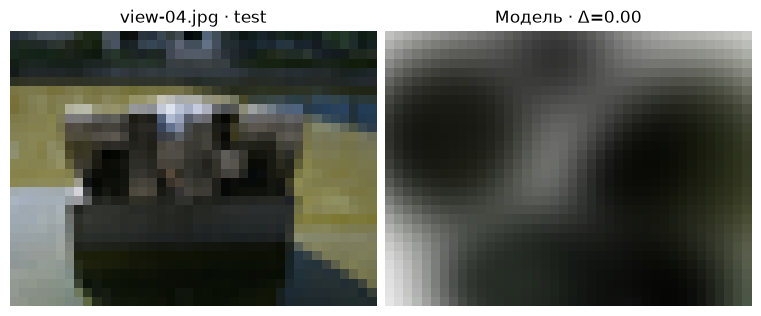

In [6]:
import torch
from reconstruction_fit import refine_scene
torch.set_num_threads(1)
trained, fit_loss = refine_scene(warm, photos, steps=30, rate=.017)
model_path = out/"static-gaussians.json"
model_path.write_text(json.dumps(trained, indent=2, allow_nan=False), encoding="utf8")
opened = json.loads(model_path.read_text(encoding="utf8"))
test_index = next(i for i,f in enumerate(photos) if f["split"]=="test")
f = photos[test_index]
h,w = f["rgb"].shape[:2]
assert np.allclose(render_scene(opened,f["camera"],w,h),render_scene(trained,f["camera"],w,h))
print("saved:", model_path.relative_to(Path.cwd()).as_posix(), " RGB MSE:", round(fit_loss[0],6), "→", round(fit_loss[-1],6))
display(view_figure(photos, opened, test_index, lang=lang)); plt.close()


## Что удалось исправить за тридцать шагов

У этой скульптуры есть удобное преимущество: можно сохранить три версии **одних и тех же 24 пятен**. В первой все серые, во второй за 12 шагов поменялся только цвет. Третья продолжает со второй и делает ещё 30 шагов, на которых меняются и цвет, и геометрия, и непрозрачность. Покажем все три версии с оставленной камеры при одном размере 40 × 30. Смена ракурса, числа пятен или разрешения испортила бы сравнение.

По восьми обучающим снимкам средний квадрат ошибки падает примерно с 0,3361 до 0,2542 после подбора цвета и до 0,0564 после совместной подгонки. На оставленном виде получаются 0,3501, 0,2652 и 0,0512. Значит, улучшение дошло хотя бы до этого ракурса. Углы, которых камера вообще не видела, в этом сравнении молчат.

Почему скачок после изменения формы так велик? У серого пятна на белом фоне есть предел. Если вес в пикселе равен 0,2, даже абсолютно чёрное пятно даст $0{,}2\cdot0+0{,}8\cdot1=0{,}8$. Для тёмного участка с яркостью 0,18 никакой подбор цвета здесь не поможет. Сдвиг центра, увеличение ширины или непрозрачности могут повысить вес. У этих изменений разные последствия для соседних пикселей: сдвиг переносит край, расширение захватывает обе стороны, а непрозрачность усиливает покрытие и закрывает лежащее глубже. По одному лучу эти причины часто неразличимы.

Старт {'train': np.float64(0.33614), 'test': np.float64(0.35014)}
Только RGB {'train': np.float64(0.25423), 'test': np.float64(0.26525)}
Все параметры {'train': np.float64(0.05643), 'test': np.float64(0.05124)}


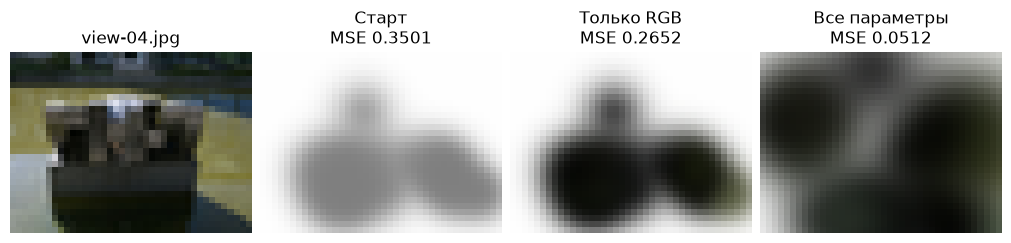

In [7]:
stages = [seed, warm, opened]
labels = ["Старт", "Только RGB", "Все параметры"] if lang=="ru" else ["Initial", "RGB only", "All parameters"]
fig, axes = plt.subplots(1,4,figsize=(10,3),layout="constrained")
axes[0].imshow(f["rgb"]); axes[0].set_title(f["name"])
for ax, model, title in zip(axes[1:], stages, labels):
    pred = render_scene(model,f["camera"],w,h)
    ax.imshow(pred)
    ax.set_title(f"{title}\nMSE {np.mean((pred-f['rgb'])**2):.4f}")
    print(title, {split:round(np.mean([row["mse"] for row in evaluate(model,photos,split)]),5)
                  for split in ("train","test")})
for ax in axes: ax.axis("off")
plt.show()

## Что открывает просмотрщик

В **static-gaussians.json** для каждого пятна лежат три координаты центра, три ширины, четыре числа поворота, три канала цвета и одна непрозрачность. Камеры лежат рядом, в наборе, потому что снимок зависит и от сцены, и от точки наблюдения. В веб-опыте урока сначала открывается `capture-browser.json`, затем `static-gaussians.json` в том же поле. Браузер рисует загруженную сцену камерами этого набора. Отложенный снимок можно сопоставить с рендером, а затем сдвинуть камеру. При сдвиге число ошибки исчезает: для нового пикселя пока нет измерения. Браузер принимает от 2 до 32 кадров, среди них хотя бы один обучающий и один проверочный, до 128 × 128 пикселей на кадр и до 128 пятен. Для набора остаётся ограничение на общий объём расчёта. Большая съёмка может целиком остаться в Python, а в просмотрщик попасть несколькими выбранными камерами. Оба файла остаются на устройстве.

На сайте набор фотографий открывается с отложенного вида. В списке наборов есть также **«Готовая скульптура · 117 пятен»**. Этот вариант обучался 1200 шагов на тех же восьми видах, по 256 обучающих пикселей за шаг. Он открывается сразу для осмотра и экспорта. При оценке полного кадра 80 × 60 MSE на view-04 равна примерно 0.00982, или 20.08 дБ. В браузере эта готовая сцена сравнивается с тем же снимком 80 × 60. [Обучение модели из 117 пятен](https://github.com/HeinrichWirth/gaussian-splatting-course/blob/main/scripts/train_photo_reference.py)

Есть ли здесь детали камня? У модели мало пятен, широта направлений ограничена, цвет одинаков при любом ракурсе. На картинке угадываются крупные массы и цвет фона, тонкие края могут теряться. Оценка качества отдельно в следующем уроке.


In [8]:
controls(lambda view, offset: view_figure(photos, opened, int(view), offset, lang),
         view=list(range(len(photos))), offset=(-.2,.2,.01,0))
print("model file:", model_path.name, " capture file: capture-browser.json")


model file: static-gaussians.json  capture file: capture-browser.json


## Из каких пятен получился один пиксель скульптуры

Теперь в кадре модель из 117 пятен. В центре снимка view-04, в столбце 40 и строке 30, фотография имеет RGB примерно $(0{,}180;\,0{,}180;\,0{,}161)$. Чтобы понять, откуда в рендере взялся другой оттенок, пройдём луч в порядке глубины и запишем для каждого пятна две величины: сколько света до него дошло ($T$) и какую долю этого остатка оно закрывает ($\alpha$).

У пятна № 25 получается $T\alpha\approx1{,}0000\cdot0{,}4726=0{,}4726$. До № 102 доходит всего 0,4843. Хотя его собственная непрозрачность в пикселе выше, 0,7529, его доля меньше: $0{,}4843\cdot0{,}7529\approx0{,}3646$. Список под снимком упорядочен **по вкладу** уже после обхода в глубину. К первым двум весам добавляются остальные пятна и остаток белого фона 0,0543. Сумма всех весов равна единице. После умножения каждого веса на его RGB получается $(0{,}164;\,0{,}167;\,0{,}151)$.

Зафиксируем геометрию и прибавим 0,01 только красному каналу № 25. Предсказание в этом пикселе увеличится на $0{,}4726\cdot0{,}01=0{,}004726$. Фотография была краснее, и здесь изменение помогло бы. В верхнем левом углу главным окажется № 13, а у № 25 будет вес около 0,112. То же изменение там поднимет красный всего на 0,00112. Судьба общей поправки решается по всем обучающим пикселям. Кадр view-04 в опыте служит для разбора уже готовой модели.

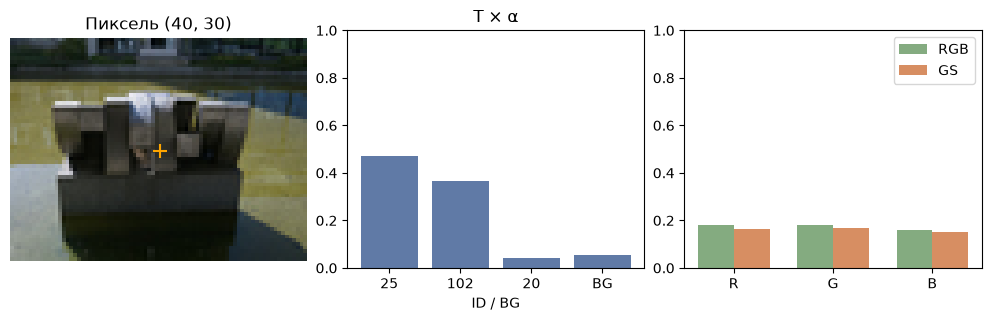

In [9]:
detail_model, detail_frame = inspect_photo.reference_photo()
def inspect_pixel(u,v):
    return inspect_photo.pixel_figure(detail_model,detail_frame,u,v,lang)
display(inspect_pixel(40,30)); plt.close()
controls(inspect_pixel,u=(0,79,1,40),v=(0,59,1,30))

## Те же фотографии в реализации авторов

Полноразмерный опыт работает в отдельном окружении официального проекта с CUDA, его расширением растеризации и совместимой NVIDIA GPU. Команды ниже выполняются в установленной реализации авторов. Здесь используются **те же результаты коррекции дисторсии**, что и в уроке 19. В папке `scene/images` лежат файлы из `capture/undistorted/images`. В `scene/sparse/0` лежит содержимое `capture/undistorted/sparse`, включая бинарные cameras.bin, images.bin и points3D.bin. Имена изображений остаются такими же, как в модели. Текстовый экспорт нужен нашему учебному загрузчику, бинарный — реализации авторов.

```sh
python train.py -s scene -m models/sculpture --eval
python render.py -m models/sculpture
python metrics.py -m models/sculpture
SIBR_gaussianViewer_app -m models/sculpture
```

SIBR здесь — установленный просмотрщик авторов, исполняемый файл из каталога bin. В Windows его имя оканчивается на .exe. Путь после `-m` ведёт к **папке модели** с настройками и сохранённым облаком в point_cloud/iteration_…/point_cloud.ply. У этого PLY другая схема и параметризация, чем у учебного JSON. Программа train.py меняет плотность и учит параметры внешнего вида в сферических гармониках. С `--eval` стандартный загрузчик COLMAP у авторов откладывает каждый восьмой снимок после сортировки по имени (при обычном разбиении). Наш опыт явно откладывает view-04. Сравнивать значения двух запусков полезно только при одинаковом наборе тестовых видов, разрешении и фоне. [Официальный проект и зависимости](https://github.com/graphdeco-inria/gaussian-splatting) · [Код разбиения кадров](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/dataset_readers.py)

## Опыт

После сохранения сцены камера переместилась. Какие числа в файле гауссиан при этом меняются?

<details><summary>Разбор</summary>

Ни одно. Новые экранные координаты, размеры следов и порядок по глубине пересчитывает рендерер. Обучение меняет саму сцену, навигация по готовой сцене меняет лишь наблюдателя.

</details>


## Если на новой съёмке получилось белое облако

<details><summary>Ошибка почти не движется. Как отделить пустой кадр от плохого цвета?</summary>

В одной обучающей камере можно проецировать несколько исходных центров прямо поверх фотографии и посмотреть глубины. Отрицательные глубины у точек перед камерой — повод сверить направление осей и преобразование позы. Центры на предмете при верном размере кадра, но почти единичный остаток фона в его середине — другой случай. Для проверки достаточно временно увеличить ширину одного пятна вдвое. Если его видимый след появился там, где лежит деталь, вопрос уже в покрытии или исходной непрозрачности. Если след появился в стороне, расширять всю сцену рано. Изменение легко отменить, а две гипотезы уже разделились.

</details>

<details><summary>На обучающих видах край резкий, а сбоку от предмета отделяется кусок. Что сохранить для разбора?</summary>

Пригодятся снимки с их именами и позами, список видов для подгонки, исходная сцена, результат и положение камеры с дефектом. Два прохода одного и того же короткого движения камеры — до и после совместной подгонки — покажут, был ли кусок уже в разреженном облаке. Проекции одной подозрительной точки на несколько обучающих фотографий отделяют ошибку исходного трека от пятна, которое ушло при обучении. Если сцена хороша только на известных снимках, следующая проверка — независимый ракурс. Его метрики и пространственный рисунок ошибки становятся предметом урока 21.

</details>